In [10]:
# setup: load the data and define the variable groups
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

df = pd.read_csv("../data/german_credit.csv")
target = "Creditability"
continuous = ["Duration of Credit (month)", "Credit Amount", "Age (years)"]
numeric = continuous + ["No of Credits at this Bank", "No of dependents"]
ordinal = ["Length of current employment", "Instalment per cent",
           "Duration in Current address", "Occupation"]
nominal = ["Account Balance", "Payment Status of Previous Credit", "Purpose",
           "Value Savings/Stocks", "Sex & Marital Status", "Guarantors",
           "Most valuable available asset", "Concurrent Credits",
           "Type of apartment", "Telephone", "Foreign Worker"]
print(df.shape)

(1000, 21)


In [11]:
# Shapiro-Wilk normality test on the continuous variables
for col in continuous:
    w, p = stats.shapiro(df[col])
    verdict = "NOT normal" if p < 0.05 else "normal"
    print(f"{col}: W = {w:.3f}, p = {p:.2e} -> {verdict}")

Duration of Credit (month): W = 0.900, p = 4.91e-25 -> NOT normal
Credit Amount: W = 0.793, p = 8.62e-34 -> NOT normal
Age (years): W = 0.918, p = 6.92e-23 -> NOT normal


## Normality: Shapiro-Wilk

| Variable | W | p | Result |
|---|---|---|---|
| Credit Amount | 0.793 | < 0.001 | Not normal |
| Duration | 0.900 | < 0.001 | Not normal |
| Age | 0.918 | < 0.001 | Not normal |

- All three continuous variables are not normal (p < 0.001), confirming the right skew seen in Phase 1.
- Credit Amount is the furthest from normal (lowest W), matching its highest skew (1.95).
- Decision: use rank-based tests (Mann-Whitney U, Spearman) instead of the t-test and Pearson.

In [12]:
# Mann-Whitney U: do good and bad customers differ on each continuous variable?
good = df[df[target] == 1]
bad = df[df[target] == 0]

for col in continuous:
    u, p = stats.mannwhitneyu(good[col], bad[col])
    prob = u / (len(good) * len(bad))
    print(f"{col}: median good = {good[col].median()}, median bad = {bad[col].median()}, "
          f"U = {u:.0f}, p = {p:.2e}, P(good > bad) = {prob:.2f}")

Duration of Credit (month): median good = 18.0, median bad = 24.0, U = 77996, p = 7.98e-11, P(good > bad) = 0.37
Credit Amount: median good = 2244.0, median bad = 2574.5, U = 93480, p = 5.92e-03, P(good > bad) = 0.45
Age (years): median good = 34.0, median bad = 31.0, U = 119972, p = 3.45e-04, P(good > bad) = 0.57


## Mann-Whitney U: good vs bad customers

| Variable | Median good | Median bad | p | P(good > bad) |
|---|---|---|---|---|
| Duration | 18 months | 24 months | < 0.001 | 0.37 |
| Credit Amount | 2,244 DM | 2,575 DM | 0.006 | 0.45 |
| Age | 34 years | 31 years | < 0.001 | 0.57 |

- All three differences are statistically significant (p < 0.05).
- Bad customers tend to take longer and larger loans; good customers tend to be older.
- Duration shows the strongest difference (P = 0.37, furthest from 0.50); Credit Amount the weakest.
- P(good > bad) = the chance that a random good customer has a higher value than a random bad one (0.50 = no difference).

In [13]:
# Welch's t-test (compares means) next to Mann-Whitney (compares ranks)
for col in continuous:
    t, p_t = stats.ttest_ind(good[col], bad[col], equal_var=False)
    u, p_u = stats.mannwhitneyu(good[col], bad[col])
    print(f"{col}: mean good = {good[col].mean():.1f}, mean bad = {bad[col].mean():.1f}, "
          f"t = {t:.2f}, p (t-test) = {p_t:.2e}, p (Mann-Whitney) = {p_u:.2e}")

Duration of Credit (month): mean good = 19.2, mean bad = 24.9, t = -6.47, p (t-test) = 2.40e-10, p (Mann-Whitney) = 7.98e-11
Credit Amount: mean good = 2985.4, mean bad = 3938.1, t = -4.26, p (t-test) = 2.48e-05, p (Mann-Whitney) = 5.92e-03
Age (years): mean good = 36.2, mean bad = 34.0, t = 2.91, p (t-test) = 3.78e-03, p (Mann-Whitney) = 3.45e-04


In [14]:
# contingency table: Account Balance vs Creditability
table = pd.crosstab(df["Account Balance"], df[target])
table

Creditability,0,1
Account Balance,,
1,135,139
2,105,164
3,14,49
4,46,348


In [15]:
# share of bad (0) and good (1) customers in each Account Balance group
shares = pd.crosstab(df["Account Balance"], df[target], normalize="index") * 100
shares.round(1)

Creditability,0,1
Account Balance,,
1,49.3,50.7
2,39.0,61.0
3,22.2,77.8
4,11.7,88.3


In [16]:
# chi-square test and Cramér's V for Account Balance
import numpy as np
chi2, p, dof, expected = stats.chi2_contingency(table)
n = table.values.sum()
v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
print(f"chi2 = {chi2:.2f}, dof = {dof}, p = {p:.2e}, Cramér's V = {v:.3f}")
print("smallest expected count:", expected.min().round(1))

chi2 = 123.72, dof = 3, p = 1.22e-26, Cramér's V = 0.352
smallest expected count: 18.9


## Chi-square: Account Balance

- Bad rate by group: overdrawn 49%, 0–200 DM 39%, >200 DM 22%, no account 12% (overall 30%).
- χ² = 123.7, dof = 3, p < 0.001 → Account Balance is linked to credit risk.
- Cramér's V = 0.35 → moderate-to-strong link.

In [18]:
# chi-square + Cramér's V for every categorical variable, ranked by strength
results = []
for col in ordinal + nominal:
    table = pd.crosstab(df[col], df[target])
    chi2, p, dof, expected = stats.chi2_contingency(table)
    v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    results.append({"variable": col, "chi2": chi2, "dof": dof, "p": p,
                    "cramers_v": v, "min_expected": expected.min()})

chi_results = pd.DataFrame(results).sort_values("cramers_v", ascending=False)
chi_results.round(3)

,variable,chi2,dof,p,cramers_v,min_expected
4,Account Balance,123.721,3,0.000,0.352,18.9
5,Payment Status of Previous Credit,61.691,4,0.000,0.248,12.0
7,Value Savings/Stocks,36.099,4,0.000,0.190,14.4
6,Purpose,33.356,9,0.000,0.183,2.7
10,Most valuable available asset,23.720,3,0.000,0.154,46.2
12,Type of apartment,18.674,2,0.000,0.137,32.1
0,Length of current employment,18.368,4,0.001,0.136,18.6
11,Concurrent Credits,12.839,2,0.002,0.113,14.1
8,Sex & Marital Status,9.605,3,0.022,0.098,15.0
9,Guarantors,6.645,2,0.036,0.082,12.3


In [21]:
# merge rare purposes (4 = appliances, 8 = retraining) into 10 = others, then re-test
purpose_merged = df["Purpose"].replace({4: 10, 8: 10})
table = pd.crosstab(purpose_merged, df[target])
chi2, p, dof, expected = stats.chi2_contingency(table)
v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
print(table)
print(f"chi2 = {chi2:.2f}, dof = {dof}, p = {p:.2e}, Cramér's V = {v:.3f}, min expected = {expected.min():.1f}")

Creditability   0    1
Purpose               
0              89  145
1              17   86
2              58  123
3              62  218
5               8   14
6              22   28
9              34   63
10             10   23
chi2 = 30.99, dof = 7, p = 6.25e-05, Cramér's V = 0.176, min expected = 6.6


## Chi-square + Cramér's V: categorical variables vs credit risk

**Significant (p < 0.05), strongest first:**

| Variable | Cramér's V | Strength |
|---|---|---|
| Account Balance | 0.352 | moderate–strong |
| Payment Status of Previous Credit | 0.248 | weak–moderate |
| Value Savings/Stocks | 0.190 | weak–moderate |
| Purpose (rare categories merged) | 0.176 | weak–moderate |
| Most valuable available asset | 0.154 | weak–moderate |
| Type of apartment | 0.137 | weak–moderate |
| Length of current employment | 0.136 | weak–moderate |
| Concurrent Credits | 0.113 | weak |
| Sex & Marital Status | 0.098 | negligible |
| Guarantors | 0.082 | negligible |
| Foreign Worker | 0.076 | negligible |

**Not significant (p ≥ 0.05):** Instalment per cent, Occupation, Telephone, Duration in Current address.

- Purpose originally failed the expected-count rule (min 2.7 < 5); merging appliances (4) and retraining (8) into others (10) fixed it (min 6.6) without changing the result.
- Surprise: "critical account" customers are the safest (17% bad), while "no credits taken" are the riskiest (62.5% bad).

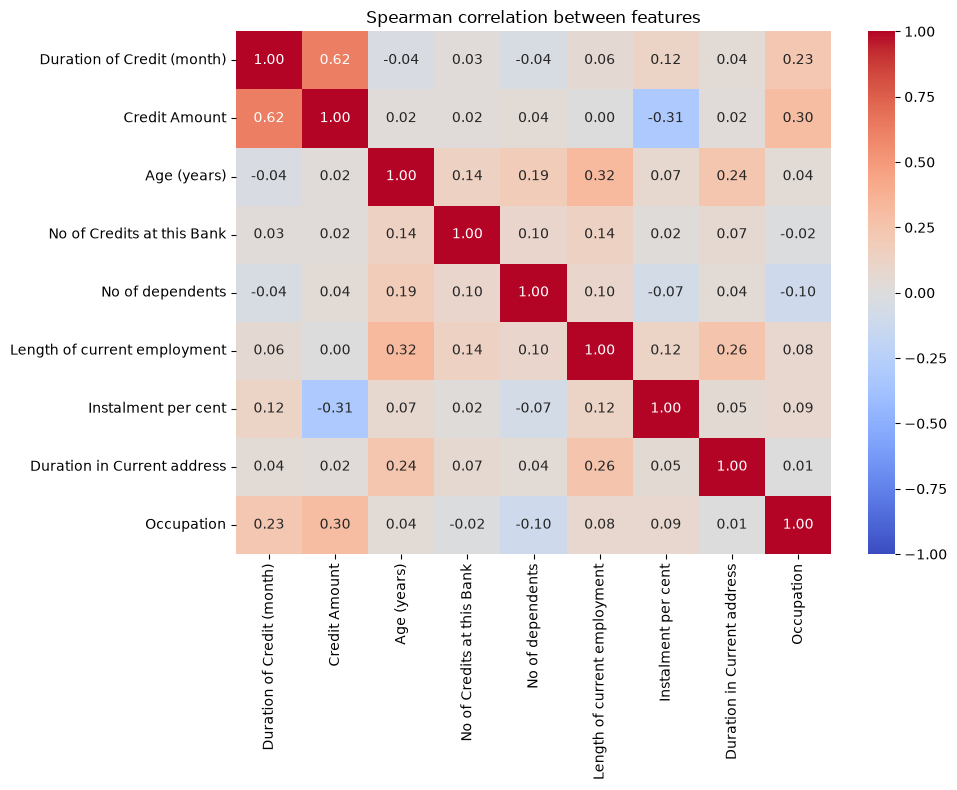

In [22]:
# Spearman correlation between all numeric and ordinal features, shown as a heatmap
corr_cols = numeric + ordinal
rho = df[corr_cols].corr(method="spearman")

plt.figure(figsize=(10, 8))
sns.heatmap(rho, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Spearman correlation between features")
plt.tight_layout()
plt.show()

## Spearman correlation between features

- Strongest pair: Duration ↔ Credit Amount (ρ = 0.62), so longer loans tend to be larger.
- No pair exceeds 0.7, so there is no severe redundancy; all features are kept.
- Credit Amount ↔ Instalment per cent is negative (ρ = −0.31): larger loans have a lower instalment as % of income, likely because they are spread over more months.
- Other moderate pairs: Age ↔ Length of employment (0.32), Credit Amount ↔ Occupation (0.30).

In [25]:
# VIF: can each feature be predicted from all the others combined?
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

X = add_constant(df[corr_cols])
vif = pd.DataFrame({
    "feature": X.columns,
    "VIF": [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
})
vif.round(2)

,feature,VIF
0,const,1.00
1,Duration of Credit (month),1.87
2,Credit Amount,2.15
3,Age (years),1.16
4,No of Credits at this Bank,1.04
5,No of dependents,1.05
6,Length of current employment,1.16
7,Instalment per cent,1.27
8,Duration in Current address,1.12
9,Occupation,1.15


## Multicollinearity: VIF

| Feature | VIF |
|---|---|
| No of Credits at this Bank | 1.04 |
| No of dependents | 1.05 |
| Duration in Current address | 1.12 |
| Occupation | 1.15 |
| Length of current employment | 1.16 |
| Age (years) | 1.16 |
| Instalment per cent | 1.27 |
| Duration of Credit (month) | 1.87 |
| Credit Amount | 2.15 |

- All VIFs are below 5 (max 2.15), so there is no multicollinearity problem.
- The highest values (Credit Amount, Duration) match the strongest Spearman pair (ρ = 0.62).
- Credit Amount's VIF of 2.15 means the other features explain about 53% of it (R² = 1 − 1/2.15); the other 47% is its own information.
- Conclusion: no feature needs to be dropped for redundancy.

In [26]:
# Weight of Evidence and Information Value for Account Balance
col = "Account Balance"
counts = pd.crosstab(df[col], df[target])
pct_good = counts[1] / counts[1].sum()
pct_bad = counts[0] / counts[0].sum()
woe = np.log(pct_good / pct_bad)
iv = ((pct_good - pct_bad) * woe).sum()

woe_table = pd.DataFrame({"good": counts[1], "bad": counts[0],
                          "% good": pct_good * 100, "% bad": pct_bad * 100, "WoE": woe})
print(woe_table.round(2))
print(f"IV = {iv:.3f}")

                 good  bad  % good  % bad   WoE
Account Balance                                
1                 139  135   19.86  45.00 -0.82
2                 164  105   23.43  35.00 -0.40
3                  49   14    7.00   4.67  0.41
4                 348   46   49.71  15.33  1.18
IV = 0.666


In [27]:
# Information Value for every categorical variable, ranked
df_iv = df.copy()
df_iv["Purpose"] = df_iv["Purpose"].replace({4: 10, 8: 10})

iv_results = []
for col in ordinal + nominal:
    counts = pd.crosstab(df_iv[col], df_iv[target])
    pct_good = counts[1] / counts[1].sum()
    pct_bad = counts[0] / counts[0].sum()
    woe = np.log(pct_good / pct_bad)
    iv = ((pct_good - pct_bad) * woe).sum()
    iv_results.append({"variable": col, "IV": iv})

iv_table = pd.DataFrame(iv_results).sort_values("IV", ascending=False)
iv_table.round(3)

,variable,IV
4,Account Balance,0.666
5,Payment Status of Previous Credit,0.293
7,Value Savings/Stocks,0.196
6,Purpose,0.156
10,Most valuable available asset,0.113
0,Length of current employment,0.086
12,Type of apartment,0.085
11,Concurrent Credits,0.058
8,Sex & Marital Status,0.045
14,Foreign Worker,0.044


## Weight of Evidence and Information Value

**Account Balance WoE:** overdrawn −0.82 · 0–200 DM −0.40 · >200 DM +0.41 · no account +1.18 → IV = 0.666 (very strong).
Negative WoE = evidence of bad credit, positive = evidence of good.

| Variable | IV | Power |
|---|---|---|
| Account Balance | 0.666 | very strong |
| Payment Status of Previous Credit | 0.293 | medium |
| Value Savings/Stocks | 0.196 | medium |
| Purpose (rare categories merged) | 0.156 | medium |
| Most valuable available asset | 0.113 | medium |
| Length of employment, Type of apartment, Concurrent Credits, Sex & Marital Status, Foreign Worker, Guarantors, Instalment per cent | 0.026–0.086 | weak |
| Occupation, Telephone, Duration in Current address | < 0.02 | useless |

- The IV ranking matches the Cramér's V ranking: both methods agree on the strongest and weakest variables.

In [28]:
# logistic regression: effect of each feature on the odds of being a GOOD customer
import statsmodels.formula.api as smf

model_df = pd.DataFrame({
    "good": df[target],
    "duration": df["Duration of Credit (month)"],
    "amount_k": df["Credit Amount"] / 1000,
    "age": df["Age (years)"],
    "balance": df["Account Balance"],
    "history": df["Payment Status of Previous Credit"],
    "savings": df["Value Savings/Stocks"],
})

logit = smf.logit("good ~ duration + amount_k + age + C(balance) + C(history) + C(savings)",
                  data=model_df).fit(disp=0)

results = pd.DataFrame({"coef": logit.params, "p_value": logit.pvalues,
                        "odds_ratio": np.exp(logit.params)})
results.round(3)

,coef,p_value,odds_ratio
Intercept,-0.601,0.212,0.548
C(balance)[T.2],0.446,0.021,1.562
C(balance)[T.3],1.012,0.003,2.752
C(balance)[T.4],1.732,0.000,5.652
C(history)[T.1],-0.114,0.814,0.892
C(history)[T.2],0.808,0.031,2.244
C(history)[T.3],0.841,0.054,2.319
C(history)[T.4],1.432,0.000,4.186
C(savings)[T.2],0.188,0.468,1.207
C(savings)[T.3],0.533,0.164,1.705


In [29]:
# global check: is the model better than knowing nothing?
print(f"Likelihood-ratio test p-value: {logit.llr_pvalue:.2e}")
print(f"McFadden pseudo R²: {logit.prsquared:.3f}")

Likelihood-ratio test p-value: 2.62e-39
McFadden pseudo R²: 0.181


In [30]:
# one test per variable: does each variable, as a whole, add information?
logit.wald_test_terms(scalar=True).table

,statistic,pvalue,df_constraint
Intercept,1.557416,2.120439e-01,1
C(balance),70.857580,2.796466e-15,3
C(history),26.573497,2.424219e-05,4
C(savings),16.578855,2.333116e-03,4
duration,14.933323,1.113782e-04,1
amount_k,1.118320,2.902804e-01,1
age,2.715026,9.940735e-02,1


In [31]:
# per-variable test with plain p-values and a yes/no significance column
wald = logit.wald_test_terms(scalar=True).table
wald = wald.drop("Intercept")
wald["significant"] = wald["pvalue"] < 0.05
wald.round(4)

,statistic,pvalue,df_constraint,significant
C(balance),70.8576,0.0000,3,True
C(history),26.5735,0.0000,4,True
C(savings),16.5789,0.0023,4,True
duration,14.9333,0.0001,1,True
amount_k,1.1183,0.2903,1,False
age,2.7150,0.0994,1,False


## Logistic regression (all features together)

Model: good ~ duration + amount (k DM) + age + account balance + payment history + savings.

**Whole model:** likelihood-ratio test p < 0.001 (much better than an empty model); McFadden pseudo R² = 0.18 (decent fit).

**Per variable (Wald test):**

| Variable | Wald χ² | df | p | Significant |
|---|---|---|---|---|
| Account Balance | 70.9 | 3 | < 0.001 | yes |
| Payment Status | 26.6 | 4 | < 0.001 | yes |
| Savings | 16.6 | 4 | 0.002 | yes |
| Duration | 14.9 | 1 | < 0.001 | yes |
| Age | 2.7 | 1 | 0.099 | no |
| Credit Amount | 1.1 | 1 | 0.290 | no |

**Key odds ratios (holding other features fixed):**
- No checking account: 5.65× the odds of being good vs overdrawn.
- Critical account history: 4.19× vs no previous credits (the chi-square surprise holds).
- Savings ≥ 1,000 DM: 2.68× vs < 100 DM.
- Each extra month of loan: odds × 0.969 (−3.1%; about −31% per extra year).

**Finding:** Credit Amount was significant alone (Mann-Whitney) but not in the model: duration already carries that information (ρ = 0.62). Age becomes borderline for the same reason.

In [33]:
# bigger logistic regression: all 11 features that were significant alone
model_df["purpose"] = df["Purpose"].replace({4: 10, 8: 10})
model_df["asset"] = df["Most valuable available asset"]
model_df["employment"] = df["Length of current employment"]
model_df["housing"] = df["Type of apartment"]
model_df["other_credits"] = df["Concurrent Credits"]

big = smf.logit("good ~ duration + amount_k + age + C(balance) + C(history) + C(savings)"
                " + C(purpose) + C(asset) + C(employment) + C(housing) + C(other_credits)",
                data=model_df).fit(disp=0)

wald_big = big.wald_test_terms(scalar=True).table.drop("Intercept")
wald_big["significant"] = wald_big["pvalue"] < 0.05
wald_big.sort_values("statistic", ascending=False).round(4)

,statistic,pvalue,df_constraint,significant
C(balance),58.6355,0.0000,3,True
C(purpose),31.1683,0.0001,7,True
C(history),19.0897,0.0008,4,True
duration,17.5925,0.0000,1,True
C(savings),16.3653,0.0026,4,True
C(employment),10.6336,0.0310,4,True
C(housing),4.9579,0.0838,2,False
C(asset),4.3658,0.2246,3,False
age,2.8607,0.0908,1,False
C(other_credits),2.3014,0.3164,2,False


## Reduced feature set

Rule: keep features that are strong alone (chi-square / IV / Mann-Whitney) and still significant together (Wald test in a logistic regression with all 11 candidates).

**Selected (5):** Account Balance, Payment Status of Previous Credit, Duration of Credit, Value Savings/Stocks, Purpose.

- Dropped: Credit Amount (p = 0.29; covered by Duration, ρ = 0.62), Age, Most valuable asset, Type of apartment, Concurrent Credits (not significant together).
- Borderline: Length of employment (p = 0.031, but weak IV 0.09); to test as an optional 6th feature.
- Compared with the 2024 report: 4 of 5 features are the same; Credit Amount is replaced by Purpose, which Pearson correlation on category codes could not detect.